In [2]:

# ============================================================
# CÉLULA 0 — ESCOLHA DOS PARÂMETROS (OBRIGATÓRIO)
# Confira/altere os valores e clique em "Confirmar parâmetros".
# RANDOM FOREST — PENSE2024
# ============================================================

import ipywidgets as widgets
from IPython.display import display, clear_output

_n_estimators = widgets.Dropdown(
    options=[
        ('100 árvores', 100),
        ('200 árvores (padrão atual)', 200),
        ('300 árvores', 300),
        ('500 árvores', 500),
        ('1000 árvores', 1000)
    ],
    value=200,
    description='N estimators:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_max_depth = widgets.Dropdown(
    options=[
        ('Sem limite (None)', None),
        ('10 níveis', 10),
        ('20 níveis', 20),
        ('30 níveis', 30),
        ('50 níveis', 50)
    ],
    value=None,
    description='Max depth:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_min_samples_split = widgets.Dropdown(
    options=[
        ('2 (padrão)', 2),
        ('5', 5),
        ('10', 10),
        ('20', 20)
    ],
    value=2,
    description='Min samples split:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_min_samples_leaf = widgets.Dropdown(
    options=[
        ('1', 1),
        ('2 (padrão atual)', 2),
        ('5', 5),
        ('10', 10),
        ('20', 20)
    ],
    value=2,
    description='Min samples leaf:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_max_features = widgets.Dropdown(
    options=[
        ('sqrt (recomendado)', 'sqrt'),
        ('log2', 'log2'),
        ('Todas as variáveis', None)
    ],
    value='sqrt',
    description='Max features:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_criterion = widgets.Dropdown(
    options=[
        ('Gini', 'gini'),
        ('Entropia', 'entropy'),
        ('Log loss', 'log_loss')
    ],
    value='gini',
    description='Criterion:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_class_weight = widgets.Dropdown(
    options=[
        ('Balanceado', 'balanced'),
        ('Balanceado por árvore', 'balanced_subsample'),
        ('Sem balanceamento', None)
    ],
    value='balanced',
    description='Class weight:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_random_state = widgets.IntText(
    value=42,
    description='Random state:',
    style={'description_width': 'initial'}
)

_test_size = widgets.Dropdown(
    options=[
        ('10% teste / 90% treino', 0.10),
        ('20% teste / 80% treino (atual)', 0.20),
        ('25% teste / 75% treino', 0.25),
        ('30% teste / 70% treino', 0.30),
        ('40% teste / 60% treino', 0.40)
    ],
    value=0.20,
    description='Divisão treino/teste:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='420px')
)

_confirmar = widgets.Button(
    description='Confirmar parâmetros',
    button_style='success',
    icon='check'
)

_status = widgets.Output()
_PARAMETROS_CONFIRMADOS = False

_painel = widgets.VBox([
    widgets.HTML('<h3>Configuração do Random Forest — PENSE2024</h3>'),
    widgets.HTML(
        '<p>Os valores atuais já estão selecionados. '
        'Confirme-os ou escolha outros antes do treinamento.</p>'
    ),
    _n_estimators,
    _max_depth,
    _min_samples_split,
    _min_samples_leaf,
    _max_features,
    _criterion,
    _class_weight,
    _random_state,
    _test_size,
    _confirmar,
    _status
], layout=widgets.Layout(
    border='1px solid #cccccc',
    padding='12px',
    width='500px'
))


def _confirmar_parametros(_):
    global N_ESTIMATORS, MAX_DEPTH, MIN_SAMPLES_SPLIT
    global MIN_SAMPLES_LEAF, MAX_FEATURES, CRITERION
    global CLASS_WEIGHT, RANDOM_STATE, TEST_SIZE
    global N_JOBS, _PARAMETROS_CONFIRMADOS

    with _status:
        clear_output(wait=True)

        N_ESTIMATORS = int(_n_estimators.value)
        MAX_DEPTH = _max_depth.value
        MIN_SAMPLES_SPLIT = int(_min_samples_split.value)
        MIN_SAMPLES_LEAF = int(_min_samples_leaf.value)
        MAX_FEATURES = _max_features.value
        CRITERION = _criterion.value
        CLASS_WEIGHT = _class_weight.value
        RANDOM_STATE = int(_random_state.value)
        TEST_SIZE = float(_test_size.value)
        N_JOBS = -1

        _PARAMETROS_CONFIRMADOS = True

        print('Parâmetros confirmados:')
        print(f'  n_estimators={N_ESTIMATORS}')
        print(f'  max_depth={MAX_DEPTH!r}')
        print(f'  min_samples_split={MIN_SAMPLES_SPLIT}')
        print(f'  min_samples_leaf={MIN_SAMPLES_LEAF}')
        print(f'  max_features={MAX_FEATURES!r}')
        print(f'  criterion={CRITERION!r}')
        print(f'  class_weight={CLASS_WEIGHT!r}')
        print(f'  random_state={RANDOM_STATE}')
        print(f'  treino/teste={1-TEST_SIZE:.0%}/{TEST_SIZE:.0%}')
        print(f'  n_jobs={N_JOBS}')
        print()
        print('Agora execute a célula de treinamento (Célula 1).')


_confirmar.on_click(_confirmar_parametros)

display(_painel)


Hiperparâmetros recebidos da Célula 0:
  N_ESTIMATORS = 200
  MAX_DEPTH = None
  MIN_SAMPLES_SPLIT = 2
  MIN_SAMPLES_LEAF = 2
  MAX_FEATURES = sqrt
  CRITERION = gini
  CLASS_WEIGHT = balanced
  TEST_SIZE = 0.2
  RANDOM_STATE = 42


## 1. Dataset overview

Dataset shape: (118036, 39)
Number of observations: 118,036
Number of columns: 39


,Data type,Missing values,Missing (%),Unique values
CAPITAL - indica se é município da capital,category,0,0.0,2
B01001A - Qual é o seu sexo?,category,0,0.0,2
"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",category,0,0.0,2
B01002 - Qual é a sua cor ou raça?,category,0,0.0,6
B01006 - Você mora com sua mãe?,category,0,0.0,3
B01007 - Você mora com seu pai?,category,0,0.0,3
B01015B - Na sua casa tem computador ou notebook?,category,0,0.0,3
B01016 - Você tem acesso à internet em sua casa?,category,0,0.0,3
"B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?",category,0,0.0,3
"B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)",category,0,0.0,3



Column names:
['CAPITAL - indica se é município da capital', 'B01001A - Qual é o seu sexo?', 'IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS', 'B01002 - Qual é a sua cor ou raça?', 'B01006 - Você mora com sua mãe?', 'B01007 - Você mora com seu pai?', 'B01015B - Na sua casa tem computador ou notebook?', 'B01016 - Você tem acesso à internet em sua casa?', 'B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?', 'B03010C - Quantas horas por dia você costuma ficar sentado(a), assistindo televisão, jogando videogame, usando computador, celular, tablet ou fazendo outras atividades sentado(a)? (NÃO contar sábado, domingo, feriados ou o tempo sentado na escola)', 'B05002A - Alguma vez na vida você tomou um copo ou uma dose de bebida alcoólica?', 'B07002 - NOS ÚLTIMOS 30 DIAS, com que frequência sua mãe, pai ou responsável sabia realmente o que você estava fazendo em seu tempo livre?', 'B07004 - NOS ÚLTIMOS 30 DIAS,

## 2. Target variable analysis

... (5 outputs left out)

## 4. Model evaluation

,Metric,Score
0,Accuracy,0.7706
1,Balanced accuracy,0.7521
2,Weighted precision,0.7769
3,Weighted recall,0.7706
4,Weighted F1-score,0.7730
5,Macro precision,0.7417
6,Macro recall,0.7521
7,Macro F1-score,0.7460
8,Majority-class baseline accuracy,0.6707



Classification report:
              precision    recall  f1-score   support

           1       0.84      0.81      0.83     15741
           3       0.64      0.70      0.67      7729

    accuracy                           0.77     23470
   macro avg       0.74      0.75      0.75     23470
weighted avg       0.78      0.77      0.77     23470



## 5. Confusion matrix

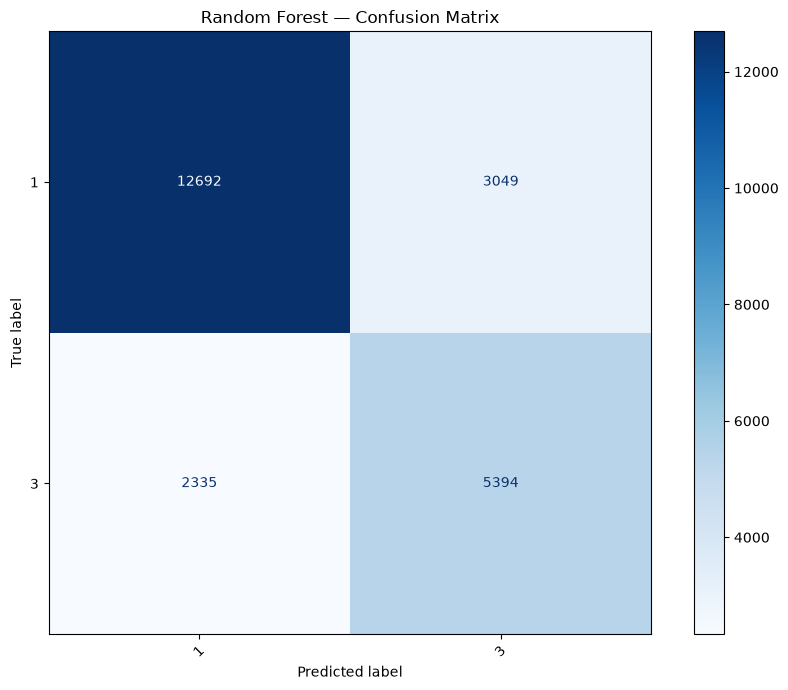

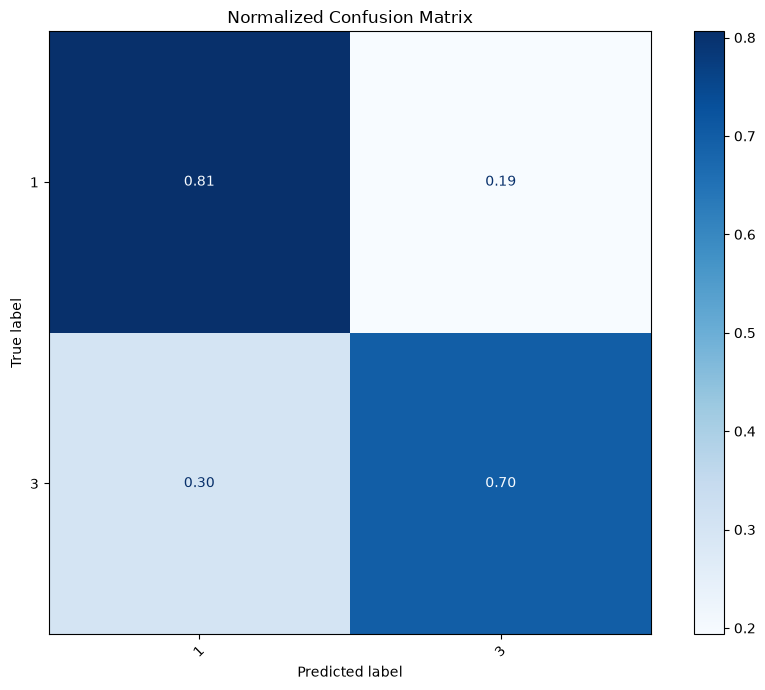

## 6. ROC-AUC

Binary ROC-AUC: 0.8305


## 7. Feature importance

Top 25 encoded categories:


,Encoded feature,Importance
87,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.076684
89,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.052798
77,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.047684
75,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.042766
79,"B12006 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.028053
104,B09016A1 - Alguma vez na vida alguém o(a) toco...,0.020460
88,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.020069
103,B09016A1 - Alguma vez na vida alguém o(a) toco...,0.020059
85,"B12007 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.019245
81,"B12006 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.018752


Top 20 original questionnaire variables:


,Original variable,Importance
26,"B12008 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.149695
23,"B12005 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.101953
24,"B12006 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.055428
31,B09016A1 - Alguma vez na vida alguém o(a) toco...,0.040788
25,"B12007 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.038025
12,"B07004 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.033850
1,B01001A - Qual é o seu sexo?,0.031262
3,B01002 - Qual é a sua cor ou raça?,0.030925
22,"B12004 - NOS ÚLTIMOS 30 DIAS, com que frequênc...",0.026190
35,"E01P117 - NOS ÚLTIMOS 12 MESES, a escola conto...",0.025548


/var/folders/6q/rl1jn5t52qg9qxc6f3l113480000gn/T/ipykernel_22992/1860680563.py:450: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


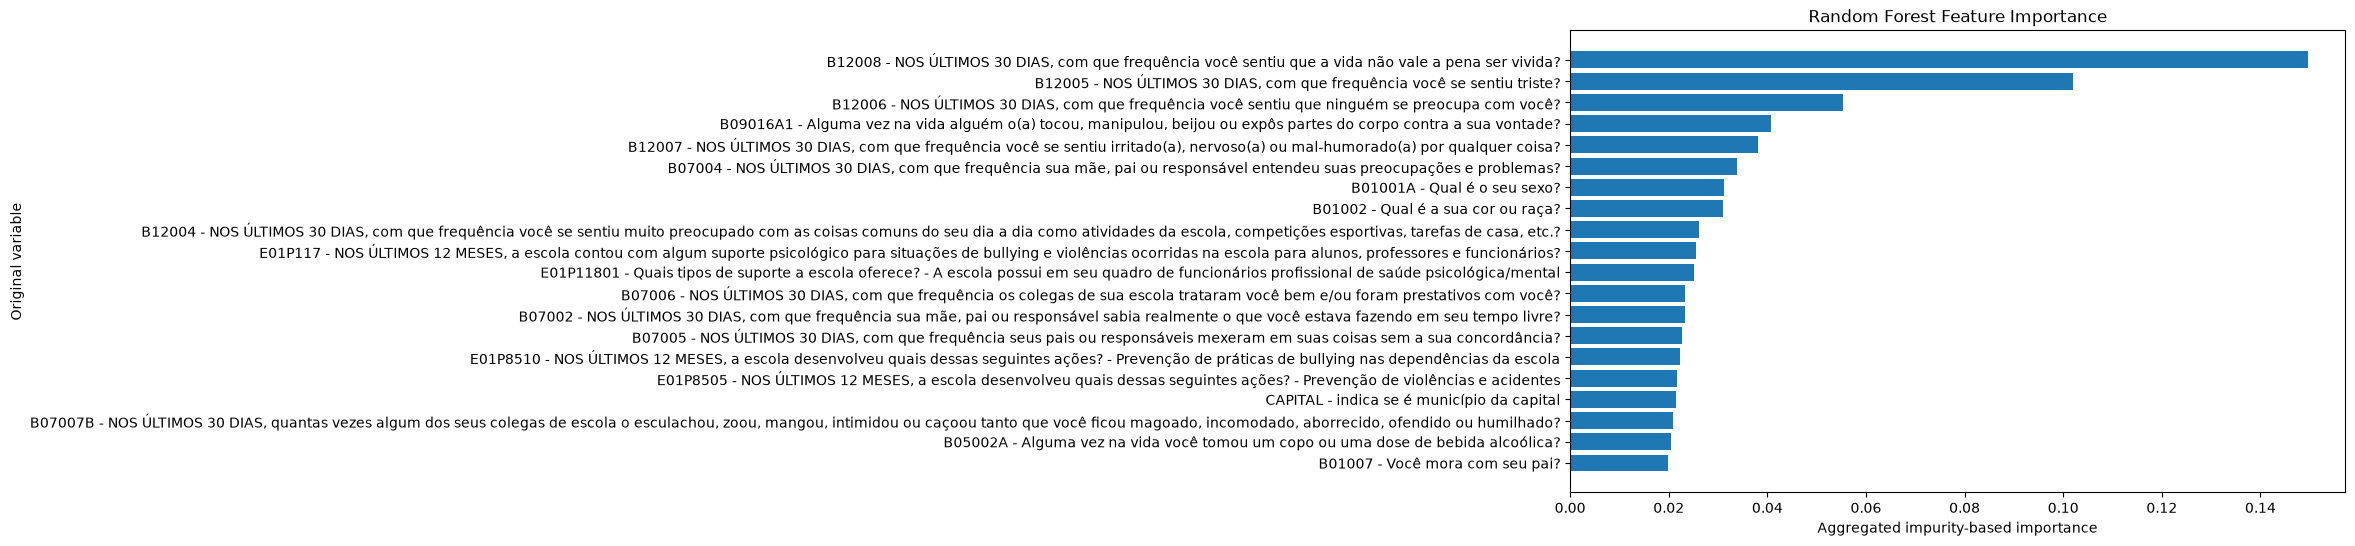

## 8. Permutation importance

Permutation importance could not be calculated: columns are missing: {'B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as aulas de educação física da escola, em quantos dias você praticou alguma atividade física?', 'B12003 - Quantos(as) amigos(as) próximos você tem?', 'B07009 - NOS ÚLTIMOS 30 DIAS, você esculachou, zombou, mangou, intimidou ou caçoou algum(a) de seus(suas) colegas da escola tanto que ele(ela) ficou magoado(a), aborrecido(a), ofendido(a) ou humilhado(a)?', 'B07013 - NOS ÚLTIMOS 30 DIAS, você se sentiu ameaçado(a), ofendido(a) ou humilhado(a) nas redes sociais ou aplicativos de celular?', 'B09002 - NOS ÚLTIMOS 30 DIAS, em quantos dias você não foi à escola porque não se sentia seguro NA ESCOLA?', 'B07012A - NOS ÚLTIMOS 30 DIAS, quantas vezes algum dos seus colegas de escola bateu (deu socos, tapas, chutes, pontapés) em você ou o machucou fisicamente de outra forma?', 'B09001 - NOS ÚLTIMOS 30 DIAS, em quantos dias você deixou de ir à escola porque não se sentia seguro NO CAMINHO

## 9. Final summary

,Item,Result
0,Target variable,"B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você..."
1,Training observations,"93,877"
2,Testing observations,"23,470"
3,Predictor variables,38
4,Number of classes,2
5,Random Forest trees,200
6,Accuracy,0.7706
7,Balanced accuracy,0.7521
8,Weighted F1-score,0.7730
9,Macro F1-score,0.7460



Analysis completed. No external result files were saved.


In [3]:

# ============================================================
# RANDOM FOREST CLASSIFIER — PENSE 2024
# All results are displayed directly in the Jupyter Notebook.
# No external files are saved.
# ============================================================

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    roc_auc_score
)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

FILE_PATH = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "07_PENSE2024_IDADE_13_A_17_CATEGORY.feather"
)

# CHANGE THIS to the column you want to predict.
TARGET_COLUMN = "B12009 - NOS ÚLTIMOS 12 MESES, alguma vez você sentiu vontade de se machucar de propósito?"

# ------------------------------------------------------------
# VALIDAR OS PARÂMETROS DEFINIDOS NA CÉLULA 0
# ------------------------------------------------------------

if not globals().get("_PARAMETROS_CONFIRMADOS", False):
    raise RuntimeError(
        "Execute a Célula 0, selecione os hiperparâmetros "
        "e clique em 'Confirmar parâmetros' antes de continuar."
    )

print("Hiperparâmetros recebidos da Célula 0:")
print(f"  N_ESTIMATORS = {N_ESTIMATORS}")
print(f"  MAX_DEPTH = {MAX_DEPTH}")
print(f"  MIN_SAMPLES_SPLIT = {MIN_SAMPLES_SPLIT}")
print(f"  MIN_SAMPLES_LEAF = {MIN_SAMPLES_LEAF}")
print(f"  MAX_FEATURES = {MAX_FEATURES}")
print(f"  CRITERION = {CRITERION}")
print(f"  CLASS_WEIGHT = {CLASS_WEIGHT}")
print(f"  TEST_SIZE = {TEST_SIZE}")
print(f"  RANDOM_STATE = {RANDOM_STATE}")

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

df = pd.read_feather(FILE_PATH)

display(Markdown("## 1. Dataset overview"))

print(f"Dataset shape: {df.shape}")
print(f"Number of observations: {len(df):,}")
print(f"Number of columns: {df.shape[1]:,}")

display(pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Missing values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique values": df.nunique(dropna=True)
}).sort_values("Missing (%)", ascending=False))

print("\nColumn names:")
print(df.columns.tolist())

if TARGET_COLUMN == "REPLACE_WITH_TARGET_COLUMN":
    raise ValueError(
        "Set TARGET_COLUMN to the name of the variable "
        "you want to predict, then rerun this cell."
    )

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Target '{TARGET_COLUMN}' was not found. "
        "Check the column names printed above."
    )

# 
# ------------------------------------------------------------
# 3. PREPARE DATA — KEEP TARGET CLASSES 1 AND 3 ONLY
# ------------------------------------------------------------

display(Markdown("## 2. Target variable analysis"))

# Keep only observations where Target is 1 or 3.
data = df.loc[df[TARGET_COLUMN].isin([1, 3])].copy()

# Remove rows with missing target values implicitly through filtering.
X = data.drop(columns=[TARGET_COLUMN]).copy()
y = data[TARGET_COLUMN].copy()

# Ensure predictors are treated as categorical.
for col in X.columns:
    X[col] = X[col].astype(object)

# Remove constant predictors.
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]
X.drop(columns=constant_cols, inplace=True)

# Remove predictors containing only missing values.
all_missing_cols = [
    col for col in X.columns
    if X[col].isna().all()
]
X.drop(columns=all_missing_cols, inplace=True)

print(f"Original observations: {len(df):,}")
print(f"Observations with Target = 1 or 3: {len(data):,}")
print(f"Observations excluded: {len(df) - len(data):,}")
print(f"Predictor variables retained: {X.shape[1]}")
print(f"Constant columns removed: {len(constant_cols)}")
print(f"All-missing columns removed: {len(all_missing_cols)}")

print("\nTarget class distribution:")
display(
    y.value_counts()
     .sort_index()
     .rename_axis("Target")
     .to_frame("Count")
     .assign(
         Percentage=lambda t:
         (t["Count"] / len(y) * 100).round(2)
     )
)

# Encode the target as categorical labels if desired.
# The original values 1 and 3 are preserved.
assert set(y.unique()) == {1, 3}, (
    "The target must contain both classes 1 and 3."
)


# ------------------------------------------------------------
# 4. TRAIN / TEST SPLIT
# ------------------------------------------------------------

# Stratification preserves class proportions when feasible.
class_counts = y.value_counts()
stratify_y = (
    y if class_counts.min() >= 2
    and len(class_counts) * 2 <= len(y)
    else None
)

if stratify_y is None:
    print(
        "Warning: stratified splitting is not feasible "
        "for this target distribution."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=stratify_y
)

print(f"\nTraining observations: {len(X_train):,}")
print(f"Testing observations: {len(X_test):,}")

# ------------------------------------------------------------
# 5. PREPROCESS CATEGORICAL VARIABLES
# ------------------------------------------------------------

categorical_cols = X_train.columns.tolist()

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("cat", categorical_pipeline, categorical_cols)
])

# ------------------------------------------------------------
# 6. RANDOM FOREST MODEL
# ------------------------------------------------------------

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        max_depth=MAX_DEPTH,
        min_samples_leaf=MIN_SAMPLES_LEAF,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS
    ))
])

display(Markdown("## 3. Train Random Forest"))

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

print("Random Forest training completed.")
print(f"Number of trees: {N_ESTIMATORS}")
print(f"Maximum depth: {MAX_DEPTH}")
print(f"Minimum samples per leaf: {MIN_SAMPLES_LEAF}")

# ------------------------------------------------------------
# 7. EVALUATION METRICS
# ------------------------------------------------------------

display(Markdown("## 4. Model evaluation"))

accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )
)

# Majority-class baseline for comparison.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

metrics_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced accuracy",
        "Weighted precision",
        "Weighted recall",
        "Weighted F1-score",
        "Macro precision",
        "Macro recall",
        "Macro F1-score",
        "Majority-class baseline accuracy"
    ],
    "Score": [
        accuracy,
        balanced_acc,
        precision,
        recall,
        f1,
        macro_precision,
        macro_recall,
        macro_f1,
        baseline_accuracy
    ]
})

display(
    metrics_df.style.format({"Score": "{:.4f}"})
)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# ------------------------------------------------------------
# 8. CONFUSION MATRIX
# ------------------------------------------------------------

display(Markdown("## 5. Confusion matrix"))

labels = rf_model.named_steps["classifier"].classes_

fig, ax = plt.subplots(figsize=(9, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

# Row-normalized confusion matrix: proportions per true class.
cm = confusion_matrix(y_test, y_pred, labels=labels)
row_sums = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_sums,
    out=np.zeros_like(cm, dtype=float),
    where=row_sums != 0
)

fig, ax = plt.subplots(figsize=(9, 7))

display_obj = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=labels
)

display_obj.plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
    colorbar=True
)

ax.set_title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. ROC-AUC (WHEN APPROPRIATE)
# ------------------------------------------------------------

display(Markdown("## 6. ROC-AUC"))

try:
    classifier = rf_model.named_steps["classifier"]
    probabilities = rf_model.predict_proba(X_test)

    if len(classifier.classes_) == 2:
        # Binary classification.
        auc = roc_auc_score(
            y_test,
            probabilities[:, 1],
            labels=classifier.classes_
        )
        print(f"Binary ROC-AUC: {auc:.4f}")

    else:
        # Multiclass ROC-AUC requires all relevant classes
        # to be represented in the test set.
        auc = roc_auc_score(
            y_test,
            probabilities,
            labels=classifier.classes_,
            multi_class="ovr",
            average="weighted"
        )
        print(f"Multiclass weighted ROC-AUC: {auc:.4f}")

except ValueError as e:
    print("ROC-AUC could not be calculated:", e)

# ------------------------------------------------------------
# 10. FEATURE IMPORTANCE
# ------------------------------------------------------------

display(Markdown("## 7. Feature importance"))

# Impurity-based importance for the one-hot encoded features.
encoder = (
    rf_model.named_steps["preprocessor"]
    .named_transformers_["cat"]
    .named_steps["onehot"]
)

encoded_names = encoder.get_feature_names_out(
    categorical_cols
)

encoded_importances = (
    rf_model.named_steps["classifier"].feature_importances_
)

encoded_importance_df = pd.DataFrame({
    "Encoded feature": encoded_names,
    "Importance": encoded_importances
}).sort_values("Importance", ascending=False)

print("Top 25 encoded categories:")
display(encoded_importance_df.head(25))

# Aggregate importance back to the original questionnaire variables.
# Each one-hot encoded category contributes to its original variable.
original_importances = {}

for col in categorical_cols:
    matching = [
        i for i, name in enumerate(encoded_names)
        if name == col or name.startswith(col + "_")
    ]
    original_importances[col] = encoded_importances[matching].sum()

importance_df = pd.DataFrame({
    "Original variable": list(original_importances.keys()),
    "Importance": list(original_importances.values())
}).sort_values("Importance", ascending=False)

print("Top 20 original questionnaire variables:")
display(importance_df.head(20))

top_n = min(20, len(importance_df))
plot_df = importance_df.head(top_n).sort_values("Importance")

fig, ax = plt.subplots(figsize=(10, max(6, top_n * 0.3)))

ax.barh(
    plot_df["Original variable"],
    plot_df["Importance"]
)

ax.set_title("Random Forest Feature Importance")
ax.set_xlabel("Aggregated impurity-based importance")
ax.set_ylabel("Original variable")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. PERMUTATION IMPORTANCE ON ORIGINAL VARIABLES
# ------------------------------------------------------------

# This measures how much test performance declines when an
# original predictor is shuffled. It can be more interpretable
# than impurity importance, but costs additional computation.

display(Markdown("## 8. Permutation importance"))

# Limit to the top original variables from the first importance
# analysis to keep computation manageable.
PERMUTATION_TOP_N = min(20, X_train.shape[1])

selected_features = importance_df[
    "Original variable"
].head(PERMUTATION_TOP_N).tolist()

try:
    perm = permutation_importance(
        rf_model,
        X_test[selected_features],
        y_test,
        scoring="f1_weighted",
        n_repeats=3,
        random_state=RANDOM_STATE,
        n_jobs=1
    )

    permutation_df = pd.DataFrame({
        "Variable": selected_features,
        "Mean importance": perm.importances_mean,
        "Std. deviation": perm.importances_std
    }).sort_values("Mean importance", ascending=False)

    display(permutation_df)

    plot_perm = permutation_df.sort_values("Mean importance")

    fig, ax = plt.subplots(
        figsize=(10, max(6, len(plot_perm) * 0.3))
    )

    ax.barh(
        plot_perm["Variable"],
        plot_perm["Mean importance"],
        xerr=plot_perm["Std. deviation"]
    )

    ax.axvline(0, linestyle="--")
    ax.set_title("Permutation Importance — Test Set")
    ax.set_xlabel("Decrease in weighted F1 when shuffled")
    ax.set_ylabel("Original variable")

    plt.tight_layout()
    plt.show()

except Exception as e:
    print("Permutation importance could not be calculated:", e)

# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

display(Markdown("## 9. Final summary"))

summary_df = pd.DataFrame({
    "Item": [
        "Target variable",
        "Training observations",
        "Testing observations",
        "Predictor variables",
        "Number of classes",
        "Random Forest trees",
        "Accuracy",
        "Balanced accuracy",
        "Weighted F1-score",
        "Macro F1-score",
        "Baseline accuracy"
    ],
    "Result": [
        TARGET_COLUMN,
        f"{len(X_train):,}",
        f"{len(X_test):,}",
        X_train.shape[1],
        y.nunique(),
        N_ESTIMATORS,
        f"{accuracy:.4f}",
        f"{balanced_acc:.4f}",
        f"{f1:.4f}",
        f"{macro_f1:.4f}",
        f"{baseline_accuracy:.4f}"
    ]
})

display(summary_df)

print("\nAnalysis completed. No external result files were saved.")


In [4]:

# ============================================================
# CÉLULA FINAL — RESPOSTAS ALEATÓRIAS E PREVISÃO RANDOM FOREST
# Não cria arquivos externos
# Target original: 1 e 3 (Target 0 excluído)
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. CONFIGURAÇÃO
# ------------------------------------------------------------

# Modelo Random Forest já treinado na célula anterior:
# rf_model = Pipeline([... RandomForestClassifier(...) ...])

colunas_perguntas = list(X.columns)

print(f"Número de variáveis preditoras: {len(colunas_perguntas)}")

if len(colunas_perguntas) != 38:
    print(
        f"ATENÇÃO: foram encontradas {len(colunas_perguntas)} "
        "variáveis, em vez de 38. O código utilizará "
        "as variáveis efetivamente usadas pelo modelo."
    )

# Novo sorteio a cada execução.
rng = np.random.default_rng()

# ------------------------------------------------------------
# 2. GERAR RESPOSTAS ALEATÓRIAS
# ------------------------------------------------------------

respostas = {}

for coluna in colunas_perguntas:

    # Categorias observadas no conjunto de treinamento.
    valores_validos = X_train[coluna].dropna().unique().tolist()

    if len(valores_validos) == 0:
        raise ValueError(
            f"Não existem respostas válidas para: {coluna}"
        )

    # Sorteia uma categoria observada para cada variável.
    respostas[coluna] = rng.choice(valores_validos)

# Criar uma observação com a mesma estrutura dos preditores.
novo_estudante = pd.DataFrame(
    [respostas],
    columns=colunas_perguntas
).astype(object)

# ------------------------------------------------------------
# 3. VERIFICAR AS CLASSES DO RANDOM FOREST
# ------------------------------------------------------------

# O código anterior utiliza um Pipeline chamado rf_model,
# cujo classificador final é chamado "classifier".

classificador = rf_model.named_steps["classifier"]
classes_modelo = list(classificador.classes_)

if len(classes_modelo) != 2:
    raise ValueError(
        f"Esperadas 2 classes (Target 1 e 3), mas o modelo "
        f"possui as classes: {classes_modelo}"
    )

# Localizar as classes originais 1 e 3, aceitando também
# rótulos armazenados como strings.
def localizar_classe_original(valor_original):
    for classe in classes_modelo:
        try:
            if str(classe).strip() == str(valor_original):
                return classe
            if float(classe) == float(valor_original):
                return classe
        except (ValueError, TypeError):
            continue

    raise ValueError(
        f"A classe original {valor_original} não foi encontrada "
        f"no modelo. Classes disponíveis: {classes_modelo}"
    )

classe_1 = localizar_classe_original(1)
classe_3 = localizar_classe_original(3)

# ------------------------------------------------------------
# 4. PREVER O TARGET
# ------------------------------------------------------------

probabilidades = rf_model.predict_proba(novo_estudante)[0]

prob_target_1 = float(
    probabilidades[classes_modelo.index(classe_1)]
)
prob_target_3 = float(
    probabilidades[classes_modelo.index(classe_3)]
)

classe_prevista = rf_model.predict(novo_estudante)[0]

if str(classe_prevista).strip() == str(classe_1).strip():
    rotulo_previsto = "Target 1"
elif str(classe_prevista).strip() == str(classe_3).strip():
    rotulo_previsto = "Target 3"
else:
    rotulo_previsto = f"Classe {classe_prevista}"

# ------------------------------------------------------------
# 5. MOSTRAR AS RESPOSTAS ALEATÓRIAS
# ------------------------------------------------------------

tabela_respostas = pd.DataFrame({
    "Variável": colunas_perguntas,
    "Resposta aleatória": [
        respostas[c] for c in colunas_perguntas
    ]
})

display(Markdown("## Respostas aleatórias geradas"))
display(tabela_respostas)

# ------------------------------------------------------------
# 6. MOSTRAR A PREVISÃO DO RANDOM FOREST
# ------------------------------------------------------------

resultado = pd.DataFrame({
    "Resultado": [
        "Probabilidade — Target 1",
        "Probabilidade — Target 3",
        "Classe prevista pelo Random Forest"
    ],
    "Valor": [
        f"{prob_target_1:.2%}",
        f"{prob_target_3:.2%}",
        rotulo_previsto
    ]
})

display(Markdown("## Resultado da previsão"))
display(resultado)

# ------------------------------------------------------------
# 7. RESUMO
# ------------------------------------------------------------

print("=" * 65)
print("RESUMO DA PREVISÃO — RANDOM FOREST")
print("=" * 65)
print(f"Variáveis utilizadas: {len(colunas_perguntas)}")
print(f"Classe prevista: {rotulo_previsto}")
print(f"Probabilidade Target 1: {prob_target_1:.2%}")
print(f"Probabilidade Target 3: {prob_target_3:.2%}")

print(
    "\nNota: as respostas são sorteadas independentemente "
    "entre as categorias observadas no treino. A combinação "
    "pode não representar um respondente real da PeNSE. "
    "As probabilidades são estimativas do modelo, não "
    "probabilidades clínicas individuais."
)


Número de variáveis preditoras: 38


## Respostas aleatórias geradas

,Variável,Resposta aleatória
0,CAPITAL - indica se é município da capital,1
1,B01001A - Qual é o seu sexo?,2
2,"IDADE_AGREG - IDADE DO ESTUDANTE, CATEGORIAS",2
3,B01002 - Qual é a sua cor ou raça?,3
4,B01006 - Você mora com sua mãe?,1
5,B01007 - Você mora com seu pai?,0
6,B01015B - Na sua casa tem computador ou notebook?,0
7,B01016 - Você tem acesso à internet em sua casa?,0
8,"B03006B - NOS ÚLTIMOS 7 DIAS, sem contar as au...",0
9,B03010C - Quantas horas por dia você costuma f...,0


## Resultado da previsão

,Resultado,Valor
0,Probabilidade — Target 1,37.41%
1,Probabilidade — Target 3,62.59%
2,Classe prevista pelo Random Forest,Target 3


RESUMO DA PREVISÃO — RANDOM FOREST
Variáveis utilizadas: 38
Classe prevista: Target 3
Probabilidade Target 1: 37.41%
Probabilidade Target 3: 62.59%

Nota: as respostas são sorteadas independentemente entre as categorias observadas no treino. A combinação pode não representar um respondente real da PeNSE. As probabilidades são estimativas do modelo, não probabilidades clínicas individuais.
